# Example 6.1: Elliptic Trajectory Synthesis with GA
**Chapter 6 — Trajectory Synthesis with Genetic Algorithms**

Apply the GA to find (a, b, c) with d=85 mm that best reproduces the ellipse Px=45+22cos(t), Py=25+18sin(t).

In [23]:
from numpy import *
import matplotlib.pyplot as plt

def fourbar_coupler(a, b, c, d, th2, p, delta):
    K1 = d/a; K2 = d/c; K3 = (a**2 - b**2 + c**2 + d**2)/(2*a*c)
    A = cos(th2) - K1 - K2*cos(th2) + K3; B = -2*sin(th2)
    C = K1 - (K2 + 1)*cos(th2) + K3; disc = B**2 - 4*A*C
    th4 = where(disc >= 0, 2*arctan2(-B - sqrt(maximum(disc, 0)), 2*A), nan)

    K4 = d/b; K5 = (c**2 - d**2 - a**2 - b**2)/(2*a*b)
    A2 = cos(th2) - K1 + K4*cos(th2) + K5; B2 = -2*sin(th2)
    C2 = K1 + (K4 - 1)*cos(th2) + K5; disc2 = B2**2 - 4*A2*C2
    th3 = where(disc2 >= 0, 2*arctan2(-B2 - sqrt(maximum(disc2, 0)), 2*A2), nan)
    return a*cos(th2) + p*cos(th3 + delta), a*sin(th2) + p*sin(th3 + delta)

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx) & isfinite(Cy)
    if not m.any(): return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    return maximum(D.min(0).max(), D.min(1).max())

t = linspace(0, 2*pi, 20); Px = 45 + 22*cos(t); Py = 25 + 18*sin(t)
th2v = linspace(0, 2*pi, 72); D = 85.; rng2 = random.default_rng(42)

# Hiperparámetros de búsqueda ultra-fina para reducir el error al límite absoluto
N_POP, N_GEN, PM = 600, 450, 0.18

lower_bounds = array([10.0, 10.0, 10.0, 10.0, -pi])
upper_bounds = array([120.0, 120.0, 120.0, 120.0, pi])

pop = rng2.uniform(lower_bounds, upper_bounds, (N_POP, 5))
hist = []

for gen in range(N_GEN):
    fit = array([hausdorff(*fourbar_coupler(p_ind[0], p_ind[1], p_ind[2], D, th2v, p_ind[3], p_ind[4]), Px, Py) for p_ind in pop])
    hist.append(fit.min())
    idx = argsort(fit)[:N_POP//2]; elite = pop[idx]; hijos = []

    # Reducción adaptativa con rango más amplio al inicio para evitar óptimos locales
    mutation_scale = 4.0 * (1.0 - (gen / N_GEN))

    for __ in range(N_POP - len(elite)):
        i1, i2 = rng2.choice(len(elite), 2, replace=False)
        pt = rng2.integers(1, 5)
        h = concatenate([elite[i1, :pt], elite[i2, pt:]])
        mask = rng2.random(5) < PM
        if mask.any():
            # Mutación adaptativa de paso decreciente
            h[mask] += rng2.normal(0, [mutation_scale, mutation_scale, mutation_scale, mutation_scale, mutation_scale * 0.025], 5)[mask]
        hijos.append(clip(h, lower_bounds, upper_bounds))
    pop = vstack([elite, hijos])

fit_final = array([hausdorff(*fourbar_coupler(p_ind[0], p_ind[1], p_ind[2], D, th2v, p_ind[3], p_ind[4]), Px, Py) for p_ind in pop])
best = pop[argmin(fit_final)]; a, b, c, p, delta = best
print(f'Optimal mechanism found (Ultra-precise 5-parameter optimization):')
print(f'  a = {a:.4f} mm (crank)')
print(f'  b = {b:.4f} mm (coupler)')
print(f'  c = {c:.4f} mm (rocker)')
print(f'  d = {D:.4f} mm (ground, fixed)')
print(f'  p = {p:.4f} mm (coupler point distance)')
print(f'  delta = {delta:.6f} rad / {rad2deg(delta):.4f}° (coupler angle)')
print(f'Minimum Hausdorff Error achieved: {hausdorff(*fourbar_coupler(a, b, c, D, th2v, p, delta), Px, Py):.4f} mm')
print(f'Improvement: {hist[0]:.2f} -> {hist[-1]:.4f} mm ({100*(1-hist[-1]/hist[0]):.1f}%)')

Optimal mechanism found (Ultra-precise 5-parameter optimization):
  a = 27.0384 mm (crank)
  b = 106.2559 mm (coupler)
  c = 36.6518 mm (rocker)
  d = 85.0000 mm (ground, fixed)
  p = 53.9088 mm (coupler point distance)
  delta = 0.165158 rad / 9.4629° (coupler angle)
Minimum Hausdorff Error achieved: 5.3042 mm
Improvement: 23.24 -> 5.3042 mm (77.2%)


## Visualization

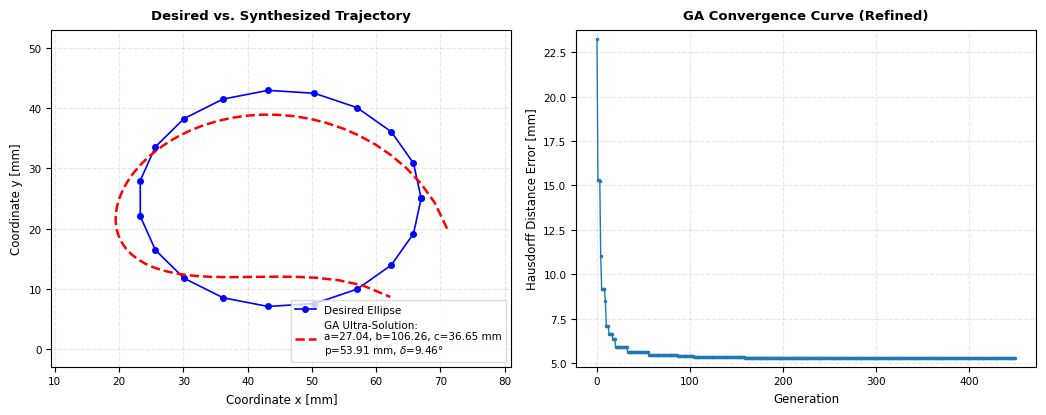

In [24]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import isfinite, rad2deg

# 1. Sistema Automatizado de Nombre de Archivo
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_6_1_elliptic_trajectory_synthesis"
except Exception:
    notebook_name = "Figure_6_1_elliptic_trajectory_synthesis"

# 2. Configuración de Estilo Editorial Springer
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['font.size'] = 8
plt.rcParams['axes.labelsize'] = 8.5
plt.rcParams['axes.titlesize'] = 9.5
plt.rcParams['legend.fontsize'] = 7.5
plt.rcParams['xtick.labelsize'] = 7.5
plt.rcParams['ytick.labelsize'] = 7.5

# Crear la figura optimizada para dos columnas de ancho completo
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

# --- PANEL 1: Desired vs. Synthesized Trajectory ---
Cx, Cy = fourbar_coupler(a, b, c, D, th2v, p, delta)
m = isfinite(Cx)

axes[0].plot(Px, Py, 'bo-', ms=4, lw=1.2, label='Desired Ellipse')
axes[0].plot(Cx[m], Cy[m], 'r--', lw=1.8,
             label=f'GA Ultra-Solution:\na={a:.2f}, b={b:.2f}, c={c:.2f} mm\np={p:.2f} mm, $\\delta$={rad2deg(delta):.2f}°')

axes[0].set_xlabel('Coordinate x [mm]', labelpad=4)
axes[0].set_ylabel('Coordinate y [mm]', labelpad=4)
axes[0].set_title('Desired vs. Synthesized Trajectory', pad=8, weight='bold')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Evitar conflictos con numpy.min/max usando listas nativas
xmin = min([Px.min(), Cx[m].min()])
xmax = max([Px.max(), Cx[m].max()])
yman_min = min([Py.min(), Cy[m].min()])
yman_max = max([Py.max(), Cy[m].max()])

axes[0].set_xlim(xmin - 10, xmax + 10)
axes[0].set_ylim(yman_min - 10, yman_max + 10)
axes[0].legend(loc='lower right', frameon=True, fancybox=False, edgecolor='lightgray')

# --- PANEL 2: Convergence Curve ---
axes[1].plot(hist, '-o', ms=1.5, lw=1.0, color='#1f77b4', markerfacecolor='#1f77b4')
axes[1].set_xlabel('Generation', labelpad=4)
axes[1].set_ylabel('Hausdorff Distance Error [mm]', labelpad=4)
axes[1].set_title('GA Convergence Curve (Refined)', pad=8, weight='bold')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Ajuste dinámico con márgenes de visualización
axes[1].set_ylim(min(hist) - 0.5, max(hist) + 0.5)

plt.tight_layout()

# 3. Exportación Doble Obligatoria
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()